# Statistical Inference Lab – Final Project
## Food Healthiness Classification Using Nutritional Information

**Name:** Kaivalya Maske  
**Roll No.:** B2-B3-48  
**Branch:** AIDS

### Objective
To analyze nutritional information of food items and classify them as **Healthy** or **Unhealthy** using a simple, transparent health score and machine-learning classification models.

### Dataset
McDonald's India Menu Nutrition Dataset

### Project Flow
**Data → Descriptive Statistics → Visualization → Selected SI Practical Concepts → Health Score → Classification → Evaluation → Prediction**

> **Important:** Healthy/Unhealthy is a project-defined academic classification, not medical or dietary advice.

## Concepts selected from the completed SI Lab practicals

Only a **small number of relevant practical concepts** are included so the project does not become unnecessarily large:

1. **Descriptive Statistics** – mean, median, variance, standard deviation and quartiles
2. **Data Visualization** – histogram, boxplot, scatter plot, and correlation heatmap
3. **Normal Distribution** – comparison with the calorie data
4. **Central Limit Theorem (CLT)** – sampling distribution of mean calories
5. **Bootstrap Estimation** – estimating the mean calorie value

The remaining practical topics are intentionally omitted because they are not essential to the food-classification objective.

### Project/ML components
- Health Score creation
- Class Imbalance handling (`class_weight='balanced'`)
- Logistic Regression
- Decision Tree
- Model evaluation
- Prediction of a new food item

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

np.random.seed(42)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load the Dataset

In [2]:
import os
import glob

# Check for local dataset first (e.g. Menu.csv with 3,381 items or India_Menu.csv)
csv_files = [f for f in ["Menu.csv", "India_Menu.csv"] if os.path.exists(f)]
if not csv_files:
    csv_files = [f for f in glob.glob("*.csv") if not f.startswith("_")]

if csv_files:
    chosen_file = "Menu.csv" if "Menu.csv" in csv_files else csv_files[0]
    print(f"Loading local dataset: {chosen_file}")
    df = pd.read_csv(chosen_file)
else:
    DATA_URL = "https://raw.githubusercontent.com/Garvitjoshi1/McDonalds-India-Menu-Nutrition-Dataset/refs/heads/main/India_Menu.csv"
    try:
        df = pd.read_csv(DATA_URL)
        print("Dataset loaded successfully from online URL.")
    except Exception:
        print("Online loading failed. Please upload Menu.csv or India_Menu.csv.")
        from google.colab import files
        uploaded = files.upload()
        df = pd.read_csv(next(iter(uploaded)))

print("Dataset shape:", df.shape)
df.head()


Dataset loaded successfully.
Dataset shape: (141, 13)


,Menu Category,Menu Items,Per Serve Size,Energy (kCal),Protein (g),Total fat (g),Sat Fat (g),Trans fat (g),Cholesterols (mg),Total carbohydrate (g),Total Sugars (g),Added Sugars (g),Sodium (mg)
0,Regular Menu,McVeggie™ Burger,168 g,402.05,10.24,13.83,5.34,0.16,2.49,56.54,7.90,4.49,706.13
1,Regular Menu,McAloo Tikki Burger®,146 g,339.52,8.50,11.31,4.27,0.20,1.47,50.27,7.05,4.07,545.34
2,Regular Menu,McSpicy™ Paneer Burger,199 g,652.76,20.29,39.45,17.12,0.18,21.85,52.33,8.35,5.27,1074.58
3,Regular Menu,Spicy Paneer Wrap,250 g,674.68,20.96,39.10,19.73,0.26,40.93,59.27,3.50,1.08,1087.46
4,Regular Menu,American Veg Burger,177 g,512.17,15.30,23.45,10.51,0.17,25.24,56.96,7.85,4.76,1051.24


## 2. Data Cleaning and Preparation

In [3]:
df = df.rename(columns={
    "Menu Category": "Category",
    "Menu Items": "Food",
    "Per Serve Size": "Serving_Size",
    "Energy (kCal)": "Calories",
    "Protein (g)": "Protein",
    "Total fat (g)": "Fat",
    "Sat Fat (g)": "Saturated_Fat",
    "Total Sugars (g)": "Sugar",
    "Sodium (mg)": "Sodium"
})

features = [
    "Calories", "Protein", "Fat",
    "Saturated_Fat", "Sugar", "Sodium"
]

food = df[["Category", "Food", "Serving_Size"] + features].copy()

for col in features:
    food[col] = pd.to_numeric(food[col], errors="coerce")

food = food.dropna(subset=features).drop_duplicates().reset_index(drop=True)

print("Cleaned dataset shape:", food.shape)
print("\nMissing values:")
print(food[features].isnull().sum())

food.head()

Cleaned dataset shape: (140, 9)

Missing values:
Calories         0
Protein          0
Fat              0
Saturated_Fat    0
Sugar            0
Sodium           0
dtype: int64


,Category,Food,Serving_Size,Calories,Protein,Fat,Saturated_Fat,Sugar,Sodium
0,Regular Menu,McVeggie™ Burger,168 g,402.05,10.24,13.83,5.34,7.90,706.13
1,Regular Menu,McAloo Tikki Burger®,146 g,339.52,8.50,11.31,4.27,7.05,545.34
2,Regular Menu,McSpicy™ Paneer Burger,199 g,652.76,20.29,39.45,17.12,8.35,1074.58
3,Regular Menu,Spicy Paneer Wrap,250 g,674.68,20.96,39.10,19.73,3.50,1087.46
4,Regular Menu,American Veg Burger,177 g,512.17,15.30,23.45,10.51,7.85,1051.24


C:\Users\Kaivalya\AppData\Local\Temp\ipykernel_39244\927561772.py:37: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i][0].boxplot(raw, vert=False, patch_artist=True,
C:\Users\Kaivalya\AppData\Local\Temp\ipykernel_39244\927561772.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i][1].boxplot(food[col], vert=False, patch_artist=True,
C:\Users\Kaivalya\AppData\Local\Temp\ipykernel_39244\927561772.py:37: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i][0].boxplot(raw, vert=False, patch_artist=True,
C:\Users\Kaivalya\AppData\Local\Temp\ipykernel_39244\927561772.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.

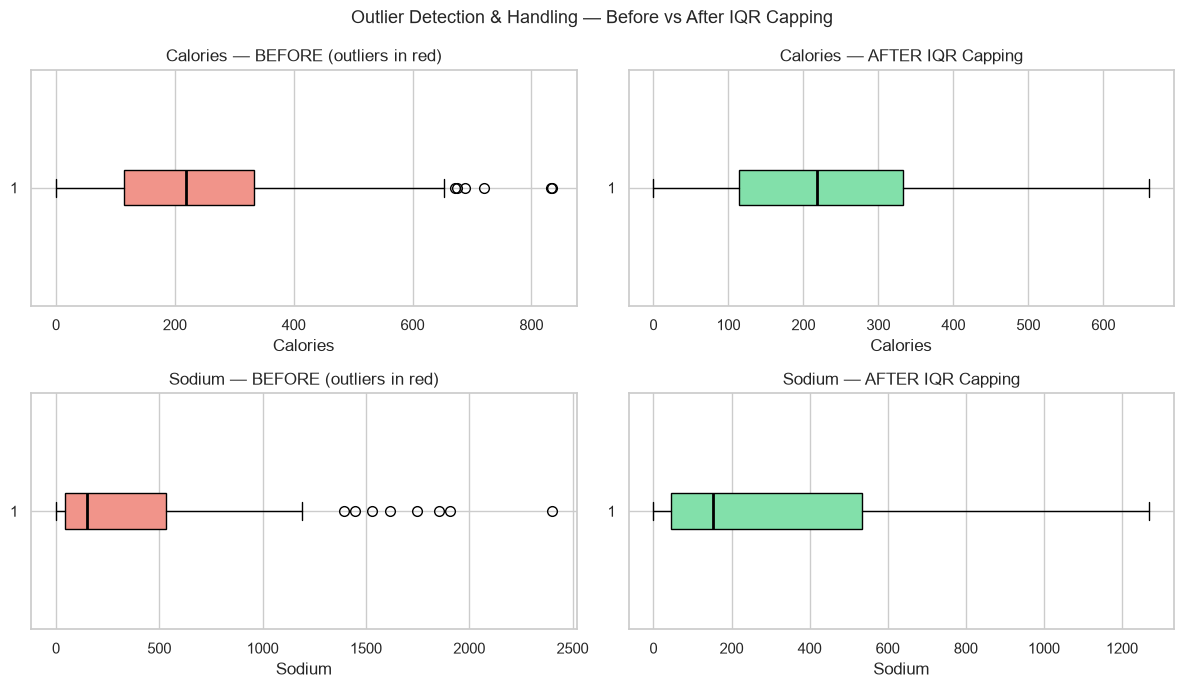


Outlier Handling Summary:


,Q1,Q3,IQR,Lower Fence,Upper Fence,Capped Low,Capped High,Total Capped
Feature,,,,,,,,
Calories,114.66,333.26,218.60,-213.24,661.15,0,6,6
Sodium,43.90,534.24,490.34,-691.62,1269.76,0,8,8


In [4]:
# ── 2a. Outlier Handling: Calories & Sodium (IQR Winsorization) ──────────────

outlier_cols = ["Calories", "Sodium"]
outlier_summary = []

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
fig.suptitle("Outlier Detection & Handling — Before vs After IQR Capping", fontsize=13)

for i, col in enumerate(outlier_cols):
    Q1  = food[col].quantile(0.25)
    Q3  = food[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_low  = int((food[col] < lower).sum())
    n_high = int((food[col] > upper).sum())

    # Save raw (before) for plotting
    raw = food[col].copy()

    # Cap (Winsorize)
    food[col] = food[col].clip(lower=lower, upper=upper)

    outlier_summary.append({
        "Feature":      col,
        "Q1":           round(Q1, 2),
        "Q3":           round(Q3, 2),
        "IQR":          round(IQR, 2),
        "Lower Fence":  round(lower, 2),
        "Upper Fence":  round(upper, 2),
        "Capped Low":   n_low,
        "Capped High":  n_high,
        "Total Capped": n_low + n_high,
    })

    # Plot Before
    axes[i][0].boxplot(raw, vert=False, patch_artist=True,
                       boxprops=dict(facecolor="#f1948a"),
                       medianprops=dict(color="black", linewidth=2),
                       flierprops=dict(marker="o", color="red", markersize=7))
    axes[i][0].set_title(f"{col} — BEFORE (outliers in red)")
    axes[i][0].set_xlabel(col)

    # Plot After
    axes[i][1].boxplot(food[col], vert=False, patch_artist=True,
                       boxprops=dict(facecolor="#82e0aa"),
                       medianprops=dict(color="black", linewidth=2),
                       flierprops=dict(marker="o", color="green", markersize=7))
    axes[i][1].set_title(f"{col} — AFTER IQR Capping")
    axes[i][1].set_xlabel(col)

plt.tight_layout()
plt.show()

# Summary table
outlier_df = pd.DataFrame(outlier_summary).set_index("Feature")
print("\nOutlier Handling Summary:")
outlier_df


## 3. Practical: Descriptive Statistics

In [5]:
desc = food[features].describe().T

desc["median"] = food[features].median()
desc["variance"] = food[features].var()
desc["IQR"] = (
    food[features].quantile(0.75)
    - food[features].quantile(0.25)
)

desc[[
    "count", "mean", "median", "std",
    "variance", "min", "25%", "50%", "75%", "max", "IQR"
]].round(2)

,count,mean,median,std,variance,min,25%,50%,75%,max,IQR
Calories,140.0,239.96,218.36,176.59,31183.36,0.0,114.66,218.36,333.26,661.15,218.60
Protein,140.0,7.36,4.72,8.22,67.62,0.0,0.63,4.72,10.60,39.47,9.98
Fat,140.0,9.94,7.74,10.36,107.29,0.0,0.44,7.74,14.06,45.18,13.62
Saturated_Fat,140.0,5.00,4.27,4.92,24.18,0.0,0.28,4.27,7.28,20.46,7.00
Sugar,140.0,15.51,9.04,15.74,247.68,0.0,2.32,9.04,26.96,64.22,24.65
Sodium,140.0,335.39,152.02,395.63,156523.77,0.0,43.90,152.02,534.24,1269.76,490.34


### Interpretation

Descriptive statistics help us understand the typical nutritional values and the spread of the data.

For example:
- **Mean** gives the average nutritional value.
- **Median** gives the middle value.
- **Standard deviation** shows variability.
- **Quartiles and IQR** help identify the spread and possible outliers.

## 4. Practical: Data Visualization

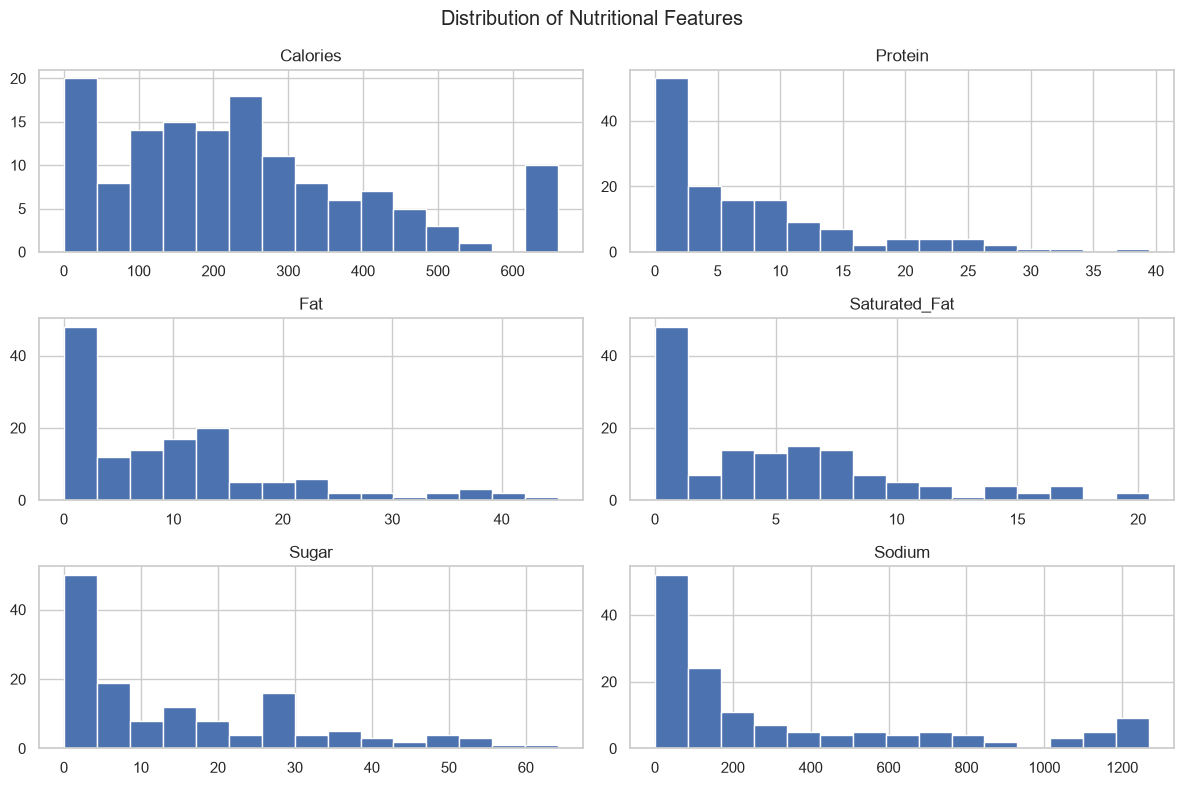

In [6]:
food[features].hist(figsize=(12, 8), bins=15)
plt.suptitle("Distribution of Nutritional Features")
plt.tight_layout()
plt.show()

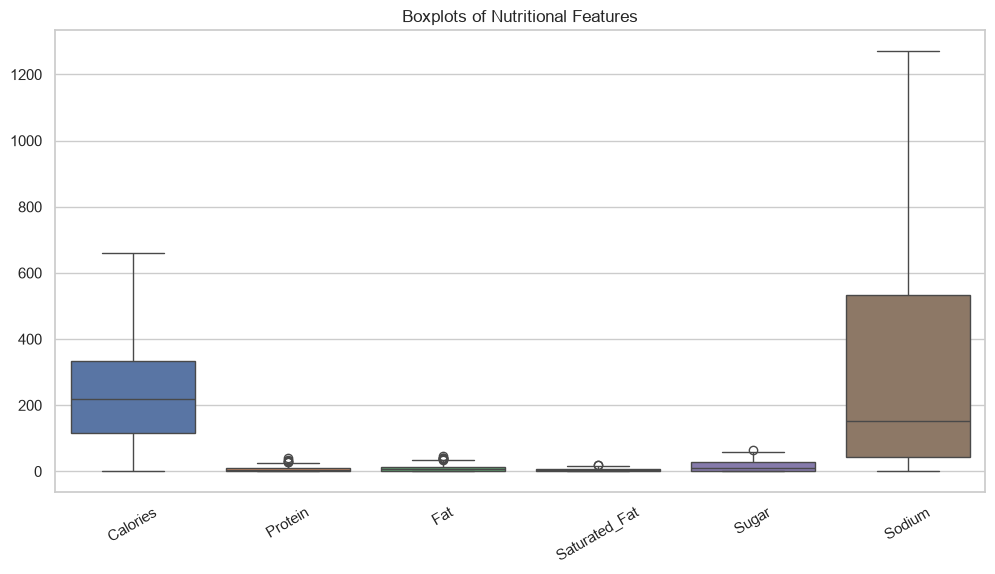

In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=food[features])
plt.xticks(rotation=30)
plt.title("Boxplots of Nutritional Features")
plt.show()

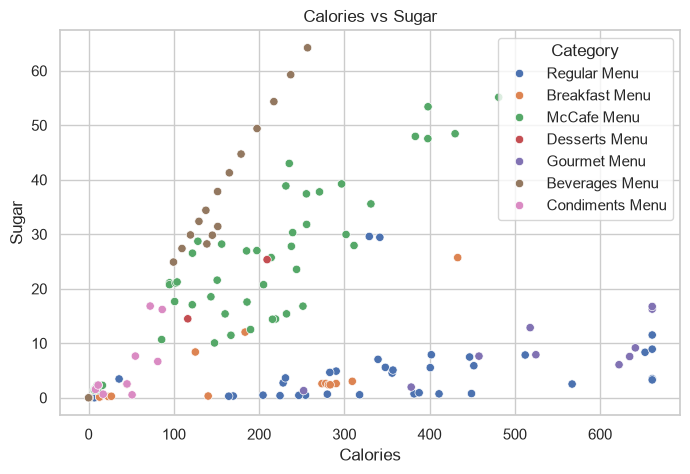

In [8]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=food, x="Calories", y="Sugar", hue="Category")
plt.title("Calories vs Sugar")
plt.show()

### 4a. Correlation Heatmap

A **correlation heatmap** shows the pairwise Pearson correlation coefficients between all nutritional features.

- Values close to **+1** indicate a strong positive relationship.
- Values close to **−1** indicate a strong negative relationship.
- Values near **0** indicate little to no linear relationship.

This helps identify multicollinearity among features, which is important for understanding model behaviour.

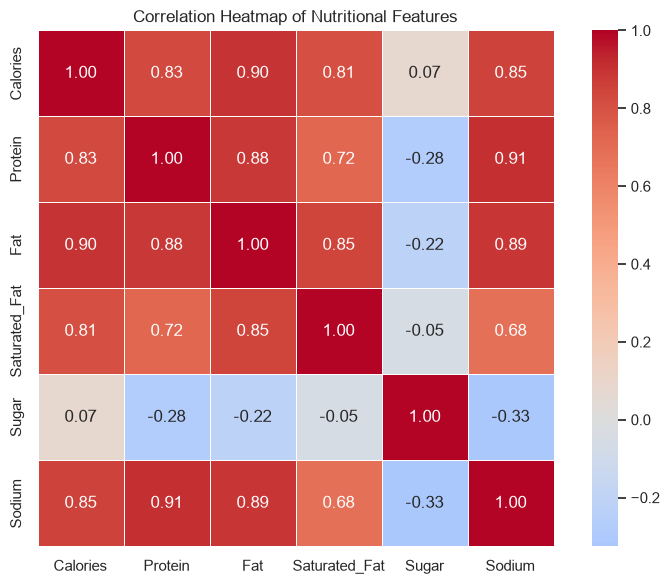


Correlation Matrix:


,Calories,Protein,Fat,Saturated_Fat,Sugar,Sodium
Calories,1.00,0.83,0.90,0.81,0.07,0.85
Protein,0.83,1.00,0.88,0.72,-0.28,0.91
Fat,0.90,0.88,1.00,0.85,-0.22,0.89
Saturated_Fat,0.81,0.72,0.85,1.00,-0.05,0.68
Sugar,0.07,-0.28,-0.22,-0.05,1.00,-0.33
Sodium,0.85,0.91,0.89,0.68,-0.33,1.00


In [9]:
# numeric_only=True required in pandas >= 2.0
corr_matrix = food[features].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True
)
plt.title("Correlation Heatmap of Nutritional Features")
plt.tight_layout()
plt.show()

print("\nCorrelation Matrix:")
corr_matrix.round(2)

## 5. Practical: Normal Distribution Comparison

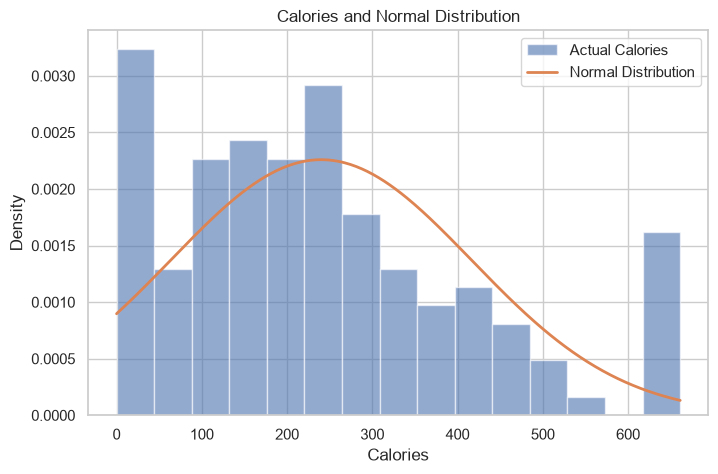

Mean (μ): 239.96
Standard Deviation (σ): 176.59


In [10]:
calories = food["Calories"]

mu = calories.mean()
sigma = calories.std()

x = np.linspace(calories.min(), calories.max(), 300)
normal_pdf = norm.pdf(x, mu, sigma)

plt.figure(figsize=(8, 5))
plt.hist(calories, bins=15, density=True, alpha=0.6, label="Actual Calories")
plt.plot(x, normal_pdf, linewidth=2, label="Normal Distribution")
plt.xlabel("Calories")
plt.ylabel("Density")
plt.title("Calories and Normal Distribution")
plt.legend()
plt.show()

print("Mean (μ):", round(mu, 2))
print("Standard Deviation (σ):", round(sigma, 2))

### Interpretation

The Normal distribution is used here as a **statistical comparison** to see how the calorie data behaves relative to a bell-shaped distribution.

It is not required for the classification model itself; it is included because it connects the project with the completed SI distribution practical.

## 6. Practical: Central Limit Theorem (CLT)

We repeatedly take samples of food items and calculate their **mean calories**.

According to the CLT, as sample size increases, the distribution of sample means tends to become more concentrated around the population mean and more approximately normal.

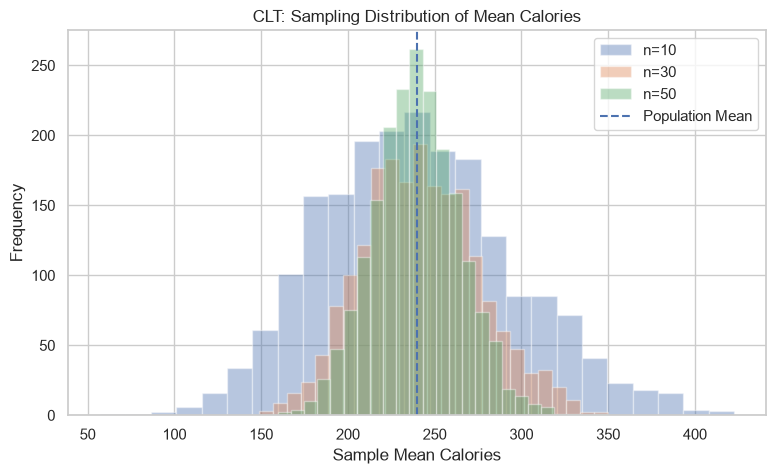

,Sample Size,Mean of Sample Means,Std. Dev. of Sample Means
0,10,239.75,55.42
1,30,241.83,33.57
2,50,239.59,24.96


In [11]:
population = food["Calories"].values
population_mean = np.mean(population)

sample_sizes = [10, 30, 50]
clt_results = []

plt.figure(figsize=(9, 5))

for n in sample_sizes:
    sample_means = []

    for _ in range(2000):
        sample = np.random.choice(population, size=n, replace=True)
        sample_means.append(np.mean(sample))

    sample_means = np.array(sample_means)

    clt_results.append({
        "Sample Size": n,
        "Mean of Sample Means": np.mean(sample_means),
        "Std. Dev. of Sample Means": np.std(sample_means)
    })

    plt.hist(sample_means, bins=25, alpha=0.4, label=f"n={n}")

plt.axvline(population_mean, linestyle="--", label="Population Mean")
plt.xlabel("Sample Mean Calories")
plt.ylabel("Frequency")
plt.title("CLT: Sampling Distribution of Mean Calories")
plt.legend()
plt.show()

pd.DataFrame(clt_results).round(2)

## 7. Core Project: Create the Health Score


Each food item receives **1 point** for each condition it satisfies.

| Nutritional condition | Points |
|---|---:|
| Calories ≤ 400 kcal | +1 |
| Total Fat ≤ 15 g | +1 |
| Saturated Fat ≤ 5 g | +1 |
| Sugar ≤ 10 g | +1 |
| Sodium ≤ 600 mg | +1 |
| Protein ≥ 8 g | +1 |

### Classification Rule
- **Health Score 4–6 → Healthy**
- **Health Score 0–3 → Unhealthy**

In [12]:
conditions = pd.DataFrame({
    "Calories": food["Calories"] <= 400,
    "Fat": food["Fat"] <= 15,
    "Saturated_Fat": food["Saturated_Fat"] <= 5,
    "Sugar": food["Sugar"] <= 10,
    "Sodium": food["Sodium"] <= 600,
    "Protein": food["Protein"] >= 8
})

food["Health_Score"] = conditions.sum(axis=1)

food["Healthy"] = np.where(
    food["Health_Score"] >= 4, 1, 0
)

food["Health_Label"] = np.where(
    food["Healthy"] == 1,
    "Healthy",
    "Unhealthy"
)

food[[
    "Food", "Calories", "Protein", "Fat",
    "Saturated_Fat", "Sugar", "Sodium",
    "Health_Score", "Health_Label"
]].head(10)

,Food,Calories,Protein,Fat,Saturated_Fat,Sugar,Sodium,Health_Score,Health_Label
0,McVeggie™ Burger,402.05000,10.24,13.83,5.34,7.90,706.1300,3,Unhealthy
1,McAloo Tikki Burger®,339.52000,8.50,11.31,4.27,7.05,545.3400,6,Healthy
2,McSpicy™ Paneer Burger,652.76000,20.29,39.45,17.12,8.35,1074.5800,2,Unhealthy
3,Spicy Paneer Wrap,661.15375,20.96,39.10,19.73,3.50,1087.4600,2,Unhealthy
4,American Veg Burger,512.17000,15.30,23.45,10.51,7.85,1051.2400,2,Unhealthy
5,Veg Maharaja Mac,661.15375,24.17,37.94,16.83,11.52,1269.7575,1,Unhealthy
6,Green Chilli Aloo Naan,356.09000,7.91,15.08,6.11,4.53,579.6000,3,Unhealthy
7,Pizza Puff,228.21000,5.45,11.44,5.72,2.73,390.7400,4,Healthy
8,Mc chicken Burger,400.80000,15.66,15.70,5.47,5.53,766.3300,2,Unhealthy
9,FILLET-O-FISH Burger,348.11000,15.44,14.16,5.79,5.58,530.5400,5,Healthy


## 8. Practical: Chi-Square Test of Independence

**Research Question:** Is there a statistically significant association between **Menu Category** (e.g., McCafe vs Regular Menu) and **Health Label** (Healthy / Unhealthy)?  
*(Example: Are some menu categories inherently healthier than others?)*

- **H₀ (Null Hypothesis):** Menu Category and Health Label are independent.
- **H₁ (Alternative Hypothesis):** Menu Category and Health Label are dependent (associated).


In [ ]:
# ── Chi-Square Test of Independence ──────────────────────────────────────────

# Step 1: Build contingency table
ct = pd.crosstab(food["Category"], food["Health_Label"])
for col in ["Healthy", "Unhealthy"]:
    if col not in ct.columns:
        ct[col] = 0
ct = ct[["Healthy", "Unhealthy"]]

print("Contingency Table (Observed Counts):")
display(ct)

# Step 2: Run chi-square test
chi2_stat, p_value, dof, expected = chi2_contingency(ct)

print(f"\nChi-Square Statistic : {chi2_stat:.4f}")
print(f"p-value              : {p_value:.4f}")
print(f"Degrees of Freedom   : {dof}")

# Step 3: Expected counts
expected_df = pd.DataFrame(
    expected.round(2),
    index=ct.index,
    columns=["Expected Healthy", "Expected Unhealthy"]
)
print("\nExpected Counts (under H₀):")
display(expected_df)

# Step 4: Standardised residuals
obs    = ct.values.astype(float)
std_res = (obs - expected) / np.sqrt(expected)
std_res_df = pd.DataFrame(
    std_res.round(3),
    index=ct.index,
    columns=["Healthy", "Unhealthy"]
)

# Step 5: Visualisations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 5a. Healthy % by category (bar chart)
ct_pct = ct.copy()
ct_pct["Total"]     = ct_pct["Healthy"] + ct_pct["Unhealthy"]
ct_pct["% Healthy"] = (ct_pct["Healthy"] / ct_pct["Total"] * 100).round(1)
cat_order = ct_pct["% Healthy"].sort_values(ascending=True).index
colors = ["#66bb6a" if v >= 50 else "#ef5350" for v in ct_pct.loc[cat_order, "% Healthy"]]
bars = axes[0].barh(cat_order, ct_pct.loc[cat_order, "% Healthy"], color=colors, edgecolor="white")
axes[0].axvline(50, color="orange", linestyle="--", linewidth=1.5, label="50% line")
for bar, val in zip(bars, ct_pct.loc[cat_order, "% Healthy"]):
    axes[0].text(val + 0.8, bar.get_y() + bar.get_height()/2, f"{val}%", va="center", fontsize=9, fontweight="bold")
axes[0].set_xlabel("% Healthy items")
axes[0].set_title("Healthy % by Menu Category")
axes[0].set_xlim(0, 115)
axes[0].legend(loc="lower right")

# 5b. Standardised residuals heatmap
sns.heatmap(std_res_df, annot=True, fmt=".2f", cmap="RdYlGn", center=0,
            linewidths=0.5, ax=axes[1], cbar_kws={"label": "Std. Residual"},
            annot_kws={"size": 10, "weight": "bold"})
axes[1].set_title("Standardised Residuals")
axes[1].set_xlabel("Health Label")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()

# Step 6: Conclusion
alpha = 0.05
if p_value < alpha:
    print(f"\n✅ REJECT H₀ (p = {p_value:.4f} < α = {alpha})")
    print("There IS a statistically significant association between Menu Category and Health Label.")
    print("Some categories are significantly healthier/unhealthier than others.")
else:
    print(f"\n❌ FAIL TO REJECT H₀ (p = {p_value:.4f} >= α = {alpha})")
    print("There is NO statistically significant association between Menu Category and Health Label.")
print(f"\nχ²({dof}) = {chi2_stat:.4f}, p = {p_value:.4f}")

## 9. Class Imbalance Check

Before training classifiers it is important to check whether the target classes are **balanced**.

- A balanced dataset has roughly equal counts of Healthy and Unhealthy items.
- An imbalanced dataset can cause a model to be biased toward the majority class, achieving high accuracy while performing poorly on the minority class.

We address imbalance by passing `class_weight='balanced'` to the classifiers, which automatically adjusts the importance of each class inversely proportional to its frequency.

Class distribution:
Health_Label
Healthy      97
Unhealthy    43
Name: count, dtype: int64

Imbalance ratio (majority : minority) = 2.26


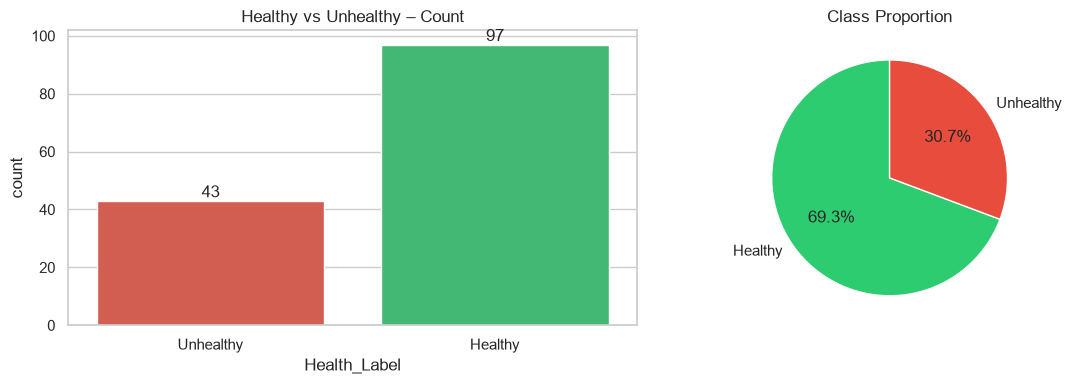

In [13]:
class_counts = food["Health_Label"].value_counts()
print("Class distribution:")
print(class_counts)
print("\nImbalance ratio (majority : minority) =",
      round(class_counts.max() / class_counts.min(), 2))

# Fixed: use hue= so seaborn accepts a dict palette (required in seaborn >= 0.12)
# Fixed: loop over all containers so bar_label works regardless of bar count
# Fixed: build pie colors dynamically to match value_counts() ordering
color_map = {"Healthy": "#2ecc71", "Unhealthy": "#e74c3c"}
pie_colors = [color_map[label] for label in class_counts.index]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
sns.countplot(
    data=food, x="Health_Label", hue="Health_Label",
    palette=color_map, legend=False, ax=axes[0]
)
axes[0].set_title("Healthy vs Unhealthy – Count")
for container in axes[0].containers:
    axes[0].bar_label(container)

# Pie chart (colors match value_counts order)
axes[1].pie(
    class_counts,
    labels=class_counts.index,
    autopct="%1.1f%%",
    colors=pie_colors,
    startangle=90
)
axes[1].set_title("Class Proportion")

plt.tight_layout()
plt.show()

## 10. Core Project: Prepare Data for Classification

In [14]:
X = food[features]
y = food["Healthy"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())

Training samples: 112
Testing samples: 28

Training class distribution:
Healthy
1    78
0    34
Name: count, dtype: int64


## 11. Logistic Regression (with class_weight='balanced')

Logistic Regression predicts the probability that a food item belongs to the **Healthy (1)** class.

The `class_weight='balanced'` parameter automatically weights the minority class higher during training, so the model does not ignore it.

In [15]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
])

logistic_model.fit(X_train, y_train)
lr_pred = logistic_model.predict(X_test)

print(classification_report(
    y_test,
    lr_pred,
    target_names=["Unhealthy", "Healthy"],
    zero_division=0
))

              precision    recall  f1-score   support

   Unhealthy       0.80      0.89      0.84         9
     Healthy       0.94      0.89      0.92        19

    accuracy                           0.89        28
   macro avg       0.87      0.89      0.88        28
weighted avg       0.90      0.89      0.89        28



## 12. Decision Tree (with class_weight='balanced')

A Decision Tree classifies food items by creating decision rules based on the nutritional features.

`max_depth=4` is chosen to limit tree complexity and prevent overfitting. `class_weight='balanced'` ensures both classes receive equal importance during training.

In [16]:
tree_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42,
    class_weight="balanced"
)

tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

print(classification_report(
    y_test,
    tree_pred,
    target_names=["Unhealthy", "Healthy"],
    zero_division=0
))

              precision    recall  f1-score   support

   Unhealthy       0.88      0.78      0.82         9
     Healthy       0.90      0.95      0.92        19

    accuracy                           0.89        28
   macro avg       0.89      0.86      0.87        28
weighted avg       0.89      0.89      0.89        28



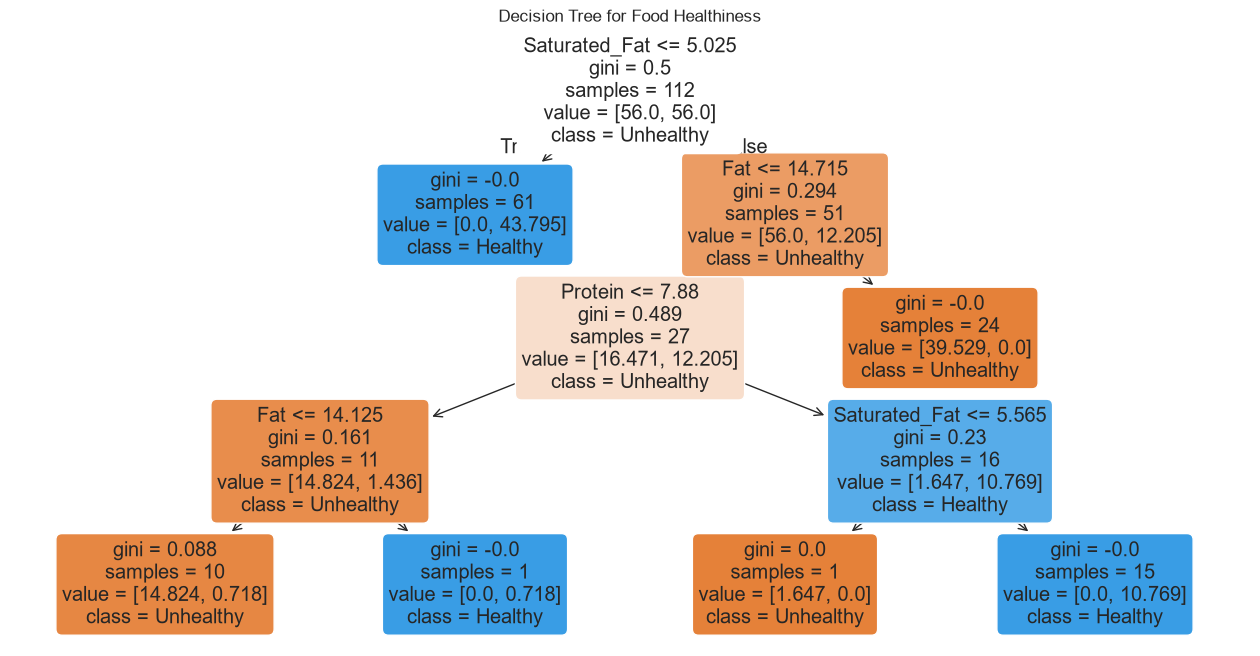

In [17]:
plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=features,
    class_names=["Unhealthy", "Healthy"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree for Food Healthiness")
plt.show()

## 13. Model Evaluation

In [18]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, tree_pred)
    ],
    "Precision": [
        precision_score(y_test, lr_pred, zero_division=0),
        precision_score(y_test, tree_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, lr_pred, zero_division=0),
        recall_score(y_test, tree_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, lr_pred, zero_division=0),
        f1_score(y_test, tree_pred, zero_division=0)
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.893,0.944,0.895,0.919
1,Decision Tree,0.893,0.900,0.947,0.923


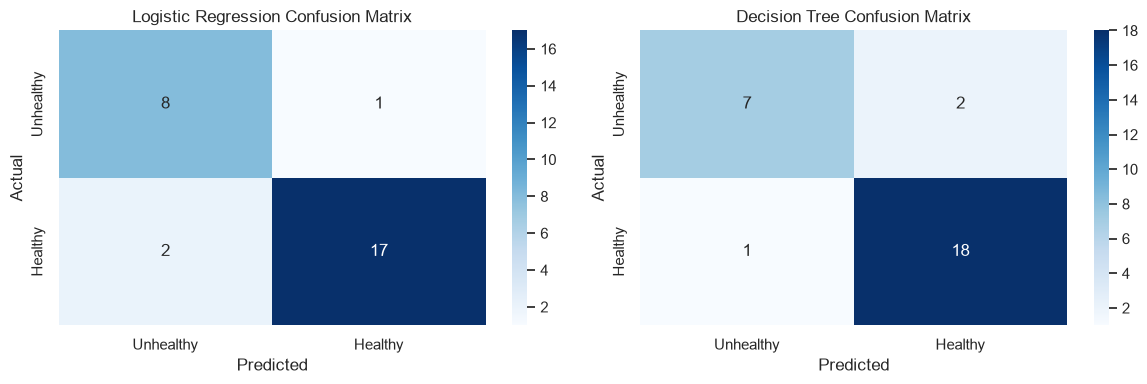

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (preds, title) in zip(axes, [
    (lr_pred, "Logistic Regression Confusion Matrix"),
    (tree_pred, "Decision Tree Confusion Matrix")
]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Unhealthy", "Healthy"],
                yticklabels=["Unhealthy", "Healthy"], ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### Metrics

- **Accuracy:** Overall percentage of correct predictions.
- **Precision:** Of the items predicted Healthy, how many were actually Healthy?
- **Recall:** Of the truly Healthy items, how many were identified?
- **F1 Score:** Balance between precision and recall.
- **Confusion Matrix:** Shows correct and incorrect classifications.

## 14. Predict a New Food Item

In [20]:
new_food = pd.DataFrame({
    "Calories": [350],
    "Protein": [12],
    "Fat": [10],
    "Saturated_Fat": [4],
    "Sugar": [8],
    "Sodium": [450]
})

prediction = logistic_model.predict(new_food)[0]
probability = logistic_model.predict_proba(new_food)[0][1]

print("New Food Nutritional Information:")
display(new_food)

print(
    "Predicted Class:",
    "Healthy" if prediction == 1 else "Unhealthy"
)

print(
    "Probability of Healthy:",
    round(probability * 100, 2), "%"
)

New Food Nutritional Information:


,Calories,Protein,Fat,Saturated_Fat,Sugar,Sodium
0,350,12,10,4,8,450


Predicted Class: Healthy
Probability of Healthy: 64.2 %


## 15. Final Conclusion

This project combines a **small, relevant portion of the Statistical Inference Lab** with the actual machine-learning objective.

### Statistical Inference part
- Descriptive statistics
- Data visualization (histograms, boxplots, scatter plot, correlation heatmap)
- Normal distribution comparison
- Central Limit Theorem
- Bootstrap estimation

### Core classification part
- Health Score creation
- Class imbalance analysis and mitigation (`class_weight='balanced'`)
- Logistic Regression
- Decision Tree
- Model evaluation
- New food prediction

### Important Limitation
The Healthy/Unhealthy target is created using the same nutritional variables that are later given to the classification models. Therefore, very high model performance can occur because the target is derived from those features. The models demonstrate the classification workflow for this academic project and should not be interpreted as a medical health assessment.

### Dataset Source
McDonald's India Menu Nutrition Dataset:
https://github.com/Garvitjoshi1/McDonalds-India-Menu-Nutrition-Dataset